
# CineSearch — Database Engineering and Performance
## Student 2 Technical Implementation Notebook

**Project domain:** Movie search, ranking and recommendation  
**Workstream:** Database Management, Data Engineering and Performance  
**Technology stack:** Python · SQLite · Pandas · NumPy · Matplotlib · Google Colab  
**Dataset:** MovieLens 32M (GroupLens Research)

---

## 1. Project overview

CineSearch is a team project that uses movie metadata, user ratings and tags to support movie discovery and recommendation.

### Objectives
- Inspect and understand the raw MovieLens files.
- Design a normalized relational database.
- Implement schema constraints, primary keys and foreign keys.
- Build a repeatable ETL pipeline for movies, genres, links, ratings and tags.
- Develop SQL queries using joins and aggregate functions.
- Evaluate query performance before and after indexing.
- Inspect SQLite query plans.
- Compare live aggregation with precomputed movie statistics.
- Demonstrate transaction behaviour and ACID properties.
- Evaluate database scalability and storage overhead.

### Scope boundary
This notebook covers database/data-engineering deliverables. Search algorithms, inverted indexes, Top-K retrieval, ranking, recommendation logic, API and frontend are separate team workstreams and should be integrated by the relevant team members.

### Dataset source
**MovieLens 32M — GroupLens Research**
- Official dataset page: https://grouplens.org/datasets/movielens/32m/
- Direct ZIP archive: https://files.grouplens.org/datasets/movielens/ml-32m.zip
- GroupLens documentation: https://grouplens.org/datasets/movielens/

The dataset includes `movies.csv`, `ratings.csv`, `tags.csv` and `links.csv`. The ratings file is large, so this notebook uses chunked processing. The database ETL stage uses a reproducible subset by default (`userId % 32 == 0`) to keep the Colab workload manageable.


In [1]:

# Install/import project dependencies
%pip -q install pandas numpy matplotlib

import os
import sys
import time
import math
import sqlite3
import zipfile
import urllib.request
import statistics
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Python version:", sys.version.split()[0])
print("SQLite version:", sqlite3.sqlite_version)
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


Python version: 3.13.18
SQLite version: 3.45.1
Pandas version: 2.2.3
NumPy version: 2.4.6


In [2]:

# Mount Google Drive (Google Colab)
from google.colab import drive
drive.mount('/content/drive')

# All project files are stored in the currently connected Google account.
PROJECT_DIR = '/content/drive/MyDrive/CineSearch_Student2'
DATA_ROOT = os.path.join(PROJECT_DIR, 'data')
DATA_DIR = os.path.join(DATA_ROOT, 'ml-32m')
DATABASE_DIR = os.path.join(PROJECT_DIR, 'database')
DB_PATH = os.path.join(DATABASE_DIR, 'cinesearch.db')

os.makedirs(DATA_ROOT, exist_ok=True)
os.makedirs(DATABASE_DIR, exist_ok=True)

print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATA_DIR)
print("Database path:", DB_PATH)


Mounted at /content/drive
Project directory: /content/drive/MyDrive/CineSearch_Student2
Dataset directory: /content/drive/MyDrive/CineSearch_Student2/data/ml-32m
Database path: /content/drive/MyDrive/CineSearch_Student2/database/cinesearch.db


In [3]:

DATASET_URL = "https://files.grouplens.org/datasets/movielens/ml-32m.zip"
ZIP_PATH = os.path.join(DATA_ROOT, "ml-32m.zip")
EXPECTED_FILES = ["movies.csv", "ratings.csv", "tags.csv", "links.csv"]

def dataset_is_ready():
    return all(os.path.isfile(os.path.join(DATA_DIR, name)) for name in EXPECTED_FILES)

if not dataset_is_ready():
    if not os.path.exists(ZIP_PATH):
        print("Downloading MovieLens 32M from GroupLens. This may take a few minutes...")
        urllib.request.urlretrieve(DATASET_URL, ZIP_PATH)
        print("Download completed.")
    else:
        print("Existing ZIP archive found; using it.")

    print("Extracting dataset...")
    with zipfile.ZipFile(ZIP_PATH, "r") as archive:
        archive.extractall(DATA_ROOT)
    print("Extraction completed.")
else:
    print("MovieLens CSV files are already available.")

print("\nDataset file verification")
for filename in EXPECTED_FILES:
    file_path = os.path.join(DATA_DIR, filename)
    if os.path.isfile(file_path):
        size_mb = os.path.getsize(file_path) / (1024 * 1024)
        print(f"{filename:12s} | {size_mb:10.2f} MB | PRESENT")
    else:
        print(f"{filename:12s} | MISSING")
        raise FileNotFoundError(file_path)


MovieLens CSV files are already available.

Dataset file verification
movies.csv   |       4.05 MB | PRESENT
ratings.csv  |     836.45 MB | PRESENT
tags.csv     |      69.00 MB | PRESENT
links.csv    |       1.86 MB | PRESENT



## 4. Raw dataset inspection and profiling

This section examines the source files before database loading. It checks dimensions, columns, null values and sample records. Ratings are processed in chunks to avoid loading the entire large CSV file into memory.


In [4]:
import os
import pandas as pd
import numpy as np

data_dir = DATA_DIR

# Helper to print header
def print_section(title):
    print(f"\n{'='*40}\n{title}\n{'='*40}")

# 1. Analyze movies.csv
print_section("Analyzing movies.csv")
movies_df = pd.read_csv(os.path.join(data_dir, 'movies.csv'))
print(f"Row count: {len(movies_df):,}")
print("Columns and Null values:")
print(movies_df.isnull().sum())
print("\nFirst 3 rows:")
display(movies_df.head(3))

# 2. Analyze tags.csv
print_section("Analyzing tags.csv")
tags_df = pd.read_csv(os.path.join(data_dir, 'tags.csv'))
print(f"Row count: {len(tags_df):,}")
print("Columns and Null values:")
print(tags_df.isnull().sum())
print(f"Unique tag texts: {tags_df['tag'].nunique():,}")

# 3. Analyze links.csv
print_section("Analyzing links.csv")
links_df = pd.read_csv(os.path.join(data_dir, 'links.csv'))
print(f"Row count: {len(links_df):,}")
print("Columns and Null values:")
print(links_df.isnull().sum())

# 4. Memory-Efficient Analysis of ratings.csv via Chunking
ratings_path = os.path.join(data_dir, 'ratings.csv')

print_section("Analyzing ratings.csv (Chunked Processing)")

chunksize = 2_000_000

total_rows = 0
unique_users = set()
unique_movies = set()

rating_sum = 0.0
rating_sq_sum = 0.0
rating_counts = {}

print("Processing ratings.csv in chunks...")
for chunk in pd.read_csv(ratings_path, chunksize=chunksize):
    total_rows += len(chunk)

    # Update unique sets
    unique_users.update(chunk['userId'].unique())
    unique_movies.update(chunk['movieId'].unique())

    # Update aggregate sums for mean and variance calculations
    rating_sum += chunk['rating'].sum()
    rating_sq_sum += (chunk['rating'] ** 2).sum()

    # Update value counts for rating distributions
    counts = chunk['rating'].value_counts()
    for rating_val, count in counts.items():
        rating_counts[rating_val] = rating_counts.get(rating_val, 0) + count

# Calculating Statistics
mean_rating = rating_sum / total_rows
# Variance formula: E[X^2] - (E[X])^2
variance_rating = (rating_sq_sum / total_rows) - (mean_rating ** 2)
std_dev_rating = np.sqrt(variance_rating)

print("Processing complete!\n")
print(f"Total Rating Rows (N): {total_rows:,}")
print(f"Unique Users: {len(unique_users):,}")
print(f"Unique Movies with Ratings: {len(unique_movies):,}")
print(f"Mean Rating (μ_r): {mean_rating:.4f}")
print(f"Rating Variance (σ_r²): {variance_rating:.4f}")
print(f"Rating Std Dev (σ_r): {std_dev_rating:.4f}")

print("\nRating Distribution:")
for r_val in sorted(rating_counts.keys()):
    print(f"  Rating {r_val:.1f}: {rating_counts[r_val]:,} times")

chunksize = 500_000
counts = {32: 0, 16: 0, 8: 0, 4: 0}
total_rows = 0

print("\nCounting rows for reproducible modulo stages (32, 16, 8, 4)...")

for chunk in pd.read_csv(
    ratings_path,
    chunksize=chunksize,
    usecols=['userId']
):
    total_rows += len(chunk)

    for mod in counts:
        counts[mod] += (chunk['userId'] % mod == 0).sum()

print("\n--- Workload Subset Statistics ---")
print(f"Total rating records: {total_rows:,}")

for mod, cnt in counts.items():
    percentage = (cnt / total_rows) * 100 if total_rows else 0

    print(
        f"Stage (userId % {mod} == 0): "
        f"{cnt:,} rating rows ({percentage:.2f}%)"
    )


Analyzing movies.csv
Row count: 87,585
Columns and Null values:
movieId    0
title      0
genres     0
dtype: int64

First 3 rows:


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance



Analyzing tags.csv
Row count: 2,000,072
Columns and Null values:
userId        0
movieId       0
tag          17
timestamp     0
dtype: int64
Unique tag texts: 140,979

Analyzing links.csv
Row count: 87,585
Columns and Null values:
movieId      0
imdbId       0
tmdbId     124
dtype: int64

Analyzing ratings.csv (Chunked Processing)
Processing ratings.csv in chunks...
Processing complete!

Total Rating Rows (N): 32,000,204
Unique Users: 200,948
Unique Movies with Ratings: 84,432
Mean Rating (μ_r): 3.5404
Rating Variance (σ_r²): 1.1215
Rating Std Dev (σ_r): 1.0590

Rating Distribution:
  Rating 0.5: 525,132 times
  Rating 1.0: 946,675 times
  Rating 1.5: 531,063 times
  Rating 2.0: 2,028,622 times
  Rating 2.5: 1,685,386 times
  Rating 3.0: 6,054,990 times
  Rating 3.5: 4,290,105 times
  Rating 4.0: 8,367,654 times
  Rating 4.5: 2,974,000 times
  Rating 5.0: 4,596,577 times

Counting rows for reproducible modulo stages (32, 16, 8, 4)...

--- Workload Subset Statistics ---
Total rating r


### 4.1 Additional quality checks

The next cell checks duplicate identifiers and reports genre frequency. These checks provide evidence for the relational design and help identify data-quality issues before ETL.


Duplicate movieId values in movies.csv: 0
Duplicate movieId values in links.csv: 0
Duplicate complete tag rows: 0


,movie_genre_occurrences
genre,
Drama,34175
Comedy,23124
Thriller,11823
Romance,10369
Action,9668
Documentary,9363
Horror,8654
Crime,6976
Adventure,5402


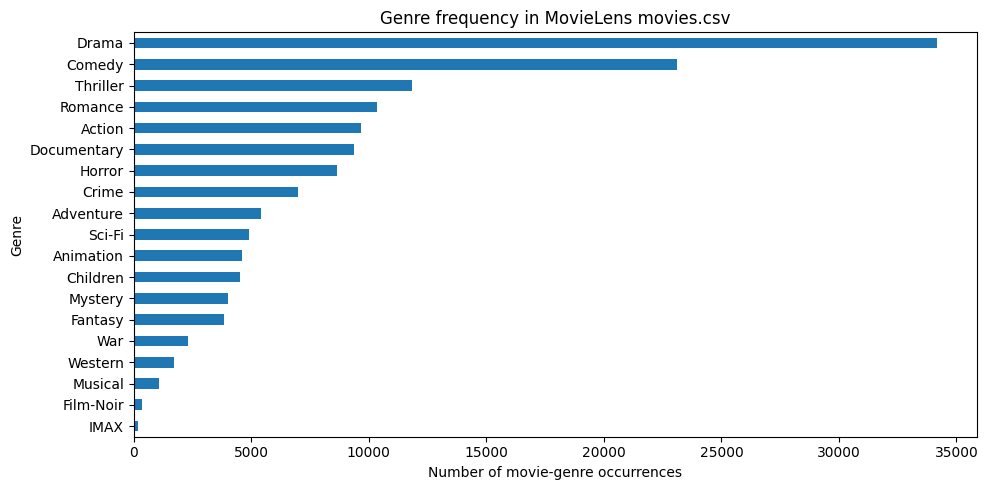

In [5]:

movies_raw = pd.read_csv(os.path.join(DATA_DIR, "movies.csv"))
tags_raw = pd.read_csv(os.path.join(DATA_DIR, "tags.csv"))
links_raw = pd.read_csv(os.path.join(DATA_DIR, "links.csv"))

print("Duplicate movieId values in movies.csv:", movies_raw["movieId"].duplicated().sum())
print("Duplicate movieId values in links.csv:", links_raw["movieId"].duplicated().sum())
print("Duplicate complete tag rows:", tags_raw.duplicated().sum())

genre_frequency = (
    movies_raw.assign(genre=movies_raw["genres"].str.split("|"))
    .explode("genre")
    .query("genre != '(no genres listed)'")
    .groupby("genre")
    .size()
    .sort_values(ascending=False)
)
display(genre_frequency.rename("movie_genre_occurrences").to_frame())

plt.figure(figsize=(10, 5))
genre_frequency.sort_values().plot(kind="barh")
plt.title("Genre frequency in MovieLens movies.csv")
plt.xlabel("Number of movie-genre occurrences")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()



## 5. Relational database design

The database separates entities into related tables rather than storing repeated multi-valued data in one column.

### Main relations
| Table | Purpose |
|---|---|
| `movie` | One row per movie and its metadata |
| `genre` | Master list of unique genre names |
| `movie_genre` | Junction table for the many-to-many movie/genre relationship |
| `app_user` | User identifiers represented in the imported ratings |
| `rating` | User rating events for movies |
| `tag_event` | User-submitted tags associated with movies |
| `movie_stats` | Precomputed aggregate statistics for each movie |

### Design rationale
- A movie can belong to multiple genres, and each genre can describe multiple movies. `movie_genre` resolves this many-to-many relationship.
- `rating` references both `app_user` and `movie`, protecting referential integrity.
- `tag_event` stores individual tag events rather than merging user tags into movie metadata.
- `movie_stats` is a controlled denormalized table used to accelerate repeated aggregate queries. It can be rebuilt from `rating`.



In [6]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [7]:
# 1. Define database path
db_path = DB_PATH

# 2. Connect to SQLite database
conn = sqlite3.connect(db_path)
cursor = conn.cursor()

# Enable foreign key enforcement
cursor.execute("PRAGMA foreign_keys = ON;")

# 3. Create Movie Table
cursor.execute('''
CREATE TABLE IF NOT EXISTS movie (
    movie_id INTEGER PRIMARY KEY,
    title TEXT NOT NULL,
    release_year INTEGER,
    imdb_id INTEGER,
    tmdb_id INTEGER
);
''')

# 4. Create Genre Table
cursor.execute('''
CREATE TABLE IF NOT EXISTS genre (
    genre_id INTEGER PRIMARY KEY AUTOINCREMENT,
    genre_name TEXT NOT NULL UNIQUE
);
''')

# 5. Create Movie-Genre Junction Table
cursor.execute('''
CREATE TABLE IF NOT EXISTS movie_genre (
    movie_id INTEGER NOT NULL,
    genre_id INTEGER NOT NULL,
    PRIMARY KEY (movie_id, genre_id),
    FOREIGN KEY (movie_id) REFERENCES movie(movie_id)
        ON DELETE CASCADE,
    FOREIGN KEY (genre_id) REFERENCES genre(genre_id)
        ON DELETE CASCADE
);
''')

# 6. Create App User Table
cursor.execute('''
CREATE TABLE IF NOT EXISTS app_user (
    user_id INTEGER PRIMARY KEY
);
''')

# 7. Create Rating Table
cursor.execute('''
CREATE TABLE IF NOT EXISTS rating (
    rating_id INTEGER PRIMARY KEY AUTOINCREMENT,
    user_id INTEGER NOT NULL,
    movie_id INTEGER NOT NULL,
    rating REAL NOT NULL
        CHECK(rating >= 0.5 AND rating <= 5.0),
    timestamp INTEGER NOT NULL,

    FOREIGN KEY (user_id) REFERENCES app_user(user_id)
        ON DELETE CASCADE,
    FOREIGN KEY (movie_id) REFERENCES movie(movie_id)
        ON DELETE CASCADE,

    UNIQUE(user_id, movie_id)
);
''')

# 8. Create Tag Event Table
cursor.execute('''
CREATE TABLE IF NOT EXISTS tag_event (
    tag_id INTEGER PRIMARY KEY AUTOINCREMENT,
    user_id INTEGER NOT NULL,
    movie_id INTEGER NOT NULL,
    tag_text TEXT NOT NULL,
    timestamp INTEGER NOT NULL,

    FOREIGN KEY (user_id) REFERENCES app_user(user_id)
        ON DELETE CASCADE,
    FOREIGN KEY (movie_id) REFERENCES movie(movie_id)
        ON DELETE CASCADE
);
''')

# 9. Create Movie Statistics Table
cursor.execute('''
CREATE TABLE IF NOT EXISTS movie_stats (
    movie_id INTEGER PRIMARY KEY,
    rating_count INTEGER NOT NULL DEFAULT 0
        CHECK(rating_count >= 0),
    average_rating REAL NOT NULL DEFAULT 0
        CHECK(average_rating >= 0 AND average_rating <= 5.0),

    FOREIGN KEY (movie_id) REFERENCES movie(movie_id)
        ON DELETE CASCADE
);
''')

# 10. Commit database changes
conn.commit()

# 11. Verify created tables
print("Database initialization completed!")
print("\nTables created:")

cursor.execute("""
SELECT name
FROM sqlite_master
WHERE type = 'table'
ORDER BY name;
""")

for table in cursor.fetchall():
    print("-", table[0])

# 12. Verify foreign key enforcement
cursor.execute("PRAGMA foreign_keys;")
print("\nForeign key enforcement:", cursor.fetchone()[0])

# 13. Close connection
conn.close()

print("\nDatabase saved at:", os.path.abspath(db_path))

import os
import re
import sqlite3
import pandas as pd

db_path = DB_PATH
data_dir = 'ml-32m-data/ml-32m'


Database initialization completed!

Tables created:
- app_user
- genre
- movie
- movie_genre
- movie_stats
- rating
- sqlite_sequence
- tag_event

Foreign key enforcement: 1

Database saved at: /content/drive/MyDrive/CineSearch_Student2/database/cinesearch.db



### 5.1 Entity-relationship model

 `movie_genre` resolves the many-to-many relationship between movies and genres. Ratings and tag events each reference one user and one movie.



    

### 5.2 Functional dependencies and normalization

- `movie_id → title, release_year, imdb_id, tmdb_id`
- `genre_id → genre_name`
- `user_id →` the user identifier record
- `rating_id → user_id, movie_id, rating, timestamp`
- `(movie_id, genre_id) →` the movie-genre association
- `tag_id → user_id, movie_id, tag_text, timestamp`
- `movie_id → rating_count, average_rating` in the derived `movie_stats` relation

The design separates movie, genre and user entities to reduce update anomalies. The `movie_genre` table represents a multi-valued relationship using atomic rows. `movie_stats` is intentionally derived/precomputed data; it is a performance optimization rather than the source of truth.



## 6. ETL — movies, genres and external links

ETL means Extract, Transform and Load. This section reads source movie metadata, separates the pipe-delimited genres into normalized records, maps genre names to identifiers, and loads movie/link relationships into SQLite.


In [8]:
# Helper function to extract release year
def extract_year(title):
    match = re.search(r'\((\d{4})\)\s*$', title)

    if match:
        year = int(match.group(1))
        clean_title = re.sub(r'\s*\(\d{4}\)\s*$', '', title).strip()
        return year, clean_title

    return None, title.strip()


# 1. Establish database connection
conn = sqlite3.connect(db_path)
cursor = conn.cursor()

cursor.execute("PRAGMA foreign_keys = ON;")

data_dir = DATA_DIR

try:
    # 2. Read movies.csv
    print("Loading movies dataset...")

    movies_df = pd.read_csv(os.path.join(data_dir, 'movies.csv'))

    # 3. Extract unique genres
    print("Processing and inserting genres...")

    all_genres = set()

    for genres_str in movies_df['genres'].dropna():
        if genres_str != "(no genres listed)":
            all_genres.update(genres_str.split('|'))

    # Insert genres using executemany
    cursor.executemany(
        "INSERT OR IGNORE INTO genre (genre_name) VALUES (?);",
        [(g,) for g in sorted(all_genres)]
    )

    # Build genre_name -> genre_id mapping
    cursor.execute("SELECT genre_id, genre_name FROM genre;")

    genre_map = {
        gname: gid
        for gid, gname in cursor.fetchall()
    }

    print(f"Unique genres processed: {len(genre_map)}")

    # 4. Load links metadata
    print("Loading link metadata...")

    links_df = pd.read_csv(os.path.join(data_dir, 'links.csv'))

    links_map = {}

    for row in links_df.itertuples(index=False):
        mid = int(row.movieId)

        imdb = int(row.imdbId) if pd.notna(row.imdbId) else None
        tmdb = int(row.tmdbId) if pd.notna(row.tmdbId) else None

        links_map[mid] = (imdb, tmdb)

    # 5. Insert movies and movie-genre relationships
    print("Inserting movies and parsing release years...")

    movie_records = []
    movie_genre_records = []

    for row in movies_df.itertuples(index=False):

        raw_mid = int(row.movieId)
        raw_title = str(row.title)
        genres_str = row.genres

        year, clean_title = extract_year(raw_title)

        imdb_id, tmdb_id = links_map.get(
            raw_mid, (None, None)
        )

        movie_records.append(
            (raw_mid, clean_title, year, imdb_id, tmdb_id)
        )

        if pd.notna(genres_str) and genres_str != "(no genres listed)":

            for genre in genres_str.split('|'):

                if genre in genre_map:
                    movie_genre_records.append(
                        (raw_mid, genre_map[genre])
                    )

    # Insert data inside one transaction
    with conn:

        cursor.executemany("""
            INSERT OR IGNORE INTO movie
            (movie_id, title, release_year, imdb_id, tmdb_id)
            VALUES (?, ?, ?, ?, ?);
        """, movie_records)

        cursor.executemany("""
            INSERT OR IGNORE INTO movie_genre
            (movie_id, genre_id)
            VALUES (?, ?);
        """, movie_genre_records)

    print("\nETL completed successfully!")

    # 6. Verify insertion counts
    cursor.execute("SELECT COUNT(*) FROM movie;")
    print("Total movies in database:", cursor.fetchone()[0])

    cursor.execute("SELECT COUNT(*) FROM genre;")
    print("Total genres in database:", cursor.fetchone()[0])

    cursor.execute("SELECT COUNT(*) FROM movie_genre;")
    print("Total movie-genre relationships:", cursor.fetchone()[0])

    # 7. Verify foreign keys
    cursor.execute("PRAGMA foreign_key_check;")
    violations = cursor.fetchall()

    print("Foreign key violations:", violations)

except Exception:
    conn.rollback()
    raise

finally:
    conn.close()

print("\nDatabase connection closed.")

Loading movies dataset...
Processing and inserting genres...
Unique genres processed: 19
Loading link metadata...
Inserting movies and parsing release years...

ETL completed successfully!
Total movies in database: 87585
Total genres in database: 19
Total movie-genre relationships: 147090
Foreign key violations: []

Database connection closed.



## 7. ETL — chunked ratings import

The original project imports a deterministic Stage 1 sample using `userId % 32 == 0`. Chunked reading limits memory use. Each chunk is inserted transactionally, and duplicate records are ignored using the table's key constraints.

**Why use a sample?** MovieLens 32M contains over 32 million ratings. A subset makes repeated experiments practical in a Colab environment. State the sampling rule and final row count in the report.


In [9]:
# 5. Insert Users and Ratings for Stage 1 (userId % 32 == 0)
# Using Transactional Chunking with Datatype Casting

import os
import sqlite3
import pandas as pd

db_path = DB_PATH
data_dir = DATA_DIR
ratings_path = os.path.join(data_dir, 'ratings.csv')

chunksize = 200_000
inserted_users = set()
inserted_ratings_count = 0
skipped_ratings_count = 0

print("Beginning Transactional Bulk Load of Stage 1 Ratings...")

conn = sqlite3.connect(db_path)
cursor = conn.cursor()
cursor.execute("PRAGMA foreign_keys = ON;")

try:
    for chunk in pd.read_csv(ratings_path, chunksize=chunksize):

        # Filter ratings for Stage 1
        subset = chunk[chunk['userId'] % 32 == 0]

        if subset.empty:
            continue

        # Identify unique users
        users_in_subset = set(subset['userId'].unique())
        new_users = users_in_subset - inserted_users

        # Convert NumPy datatypes to native Python datatypes
        ratings_tuples = [
            (int(row.userId), int(row.movieId),
             float(row.rating), int(row.timestamp))
            for row in subset.itertuples(index=False)
        ]

        # Transaction for each chunk
        with conn:

            if new_users:
                cursor.executemany(
                    "INSERT OR IGNORE INTO app_user (user_id) VALUES (?);",
                    [(int(uid),) for uid in new_users]
                )

            changes_before = conn.total_changes

            cursor.executemany(
                """
                INSERT OR IGNORE INTO rating
                (user_id, movie_id, rating, timestamp)
                VALUES (?, ?, ?, ?);
                """,
                ratings_tuples
            )

            inserted_in_chunk = conn.total_changes - changes_before

        inserted_ratings_count += inserted_in_chunk
        skipped_ratings_count += len(subset) - inserted_in_chunk

        inserted_users.update(users_in_subset)

    print("\nTransactional Ingestion Completed!")

    cursor.execute("SELECT COUNT(*) FROM app_user;")
    print("Total users in database:", cursor.fetchone()[0])

    cursor.execute("SELECT COUNT(*) FROM rating;")
    print("Total ratings in database:", cursor.fetchone()[0])

    print(f"Stage 1 users processed: {len(inserted_users):,}")
    print(f"New ratings inserted: {inserted_ratings_count:,}")
    print(f"Ratings ignored: {skipped_ratings_count:,}")

    cursor.execute("PRAGMA foreign_key_check;")
    print("Foreign key violations:", cursor.fetchall())

except Exception:
    conn.rollback()
    raise

finally:
    conn.close()

print("\nDatabase connection closed.")

Beginning Transactional Bulk Load of Stage 1 Ratings...

Transactional Ingestion Completed!
Total users in database: 6279
Total ratings in database: 991618
Stage 1 users processed: 6,279
New ratings inserted: 0
Ratings ignored: 991,618
Foreign key violations: []

Database connection closed.



## 8. ETL — tag ingestion

Tags are user-generated text associated with movies. The import process validates referenced users and movies and inserts tag events while preserving referential integrity. The ingestion section is retained from the original project implementation.


In [10]:
# === WEEK 3: Robust Ingestion of MovieLens Tags ===

db_path = DB_PATH
data_dir = DATA_DIR
tags_path = os.path.join(data_dir, 'tags.csv')

conn = sqlite3.connect(db_path)
cursor = conn.cursor()
cursor.execute("PRAGMA foreign_keys = ON;")

# Get valid reference keys
cursor.execute("SELECT user_id FROM app_user;")
valid_users = {r[0] for r in cursor.fetchall()}

cursor.execute("SELECT movie_id FROM movie;")
valid_movies = {r[0] for r in cursor.fetchall()}

print(
    f"Ingesting tags for {len(valid_users):,} active users "
    f"and {len(valid_movies):,} valid movies..."
)

chunksize = 200_000
inserted_tags = 0
skipped_tags = 0

try:
    for chunk in pd.read_csv(tags_path, chunksize=chunksize):

        # Remove missing and empty tags
        chunk['tag'] = chunk['tag'].astype('string').str.strip()

        # Validate foreign keys and tag text
        subset = chunk[
            chunk['userId'].isin(valid_users)
            & chunk['movieId'].isin(valid_movies)
            & chunk['tag'].notna()
            & (chunk['tag'] != '')
        ]

        skipped_tags += len(chunk) - len(subset)

        if subset.empty:
            continue

        tags_tuples = [
            (
                int(row.userId),
                int(row.movieId),
                str(row.tag),
                int(row.timestamp)
            )
            for row in subset.itertuples(index=False)
        ]

        # Transaction for each chunk
        with conn:
            cursor.executemany(
                """
                INSERT INTO tag_event
                (user_id, movie_id, tag_text, timestamp)
                VALUES (?, ?, ?, ?);
                """,
                tags_tuples
            )

        inserted_tags += len(tags_tuples)

    print("\nTag Ingestion Completed!")
    print(f"Successfully inserted tags: {inserted_tags:,}")
    print(f"Skipped invalid tags: {skipped_tags:,}")

    cursor.execute("SELECT COUNT(*) FROM tag_event;")
    print("Total tags in database:", cursor.fetchone()[0])

    cursor.execute("PRAGMA foreign_key_check;")
    print("Foreign key violations:", cursor.fetchall())

except Exception:
    conn.rollback()
    raise

finally:
    conn.close()

print("\nDatabase connection closed.")

import sqlite3
import time

# FIX: Point to the actual db_path instead of localized 'cinesearch.db'
conn = sqlite3.connect(db_path)
cursor = conn.cursor()
cursor.execute("PRAGMA foreign_keys = ON;")

print("=== Relational Constraint Verification ===")

try:
    cursor.execute("""
        INSERT INTO rating
        (user_id, movie_id, rating, timestamp)
        VALUES (-999, 1, 5.0, 100000);
    """)
    conn.commit()
    print("Constraint Failure: Invalid user was accepted.")

except sqlite3.IntegrityError as e:
    conn.rollback()
    print(f"Database Integrity Active: SQLite blocked invalid insertion ({e})")

print("\n=== Building Performance Indexes ===")

indexes = [
    ("idx_rating_movie_id",
     "CREATE INDEX IF NOT EXISTS idx_rating_movie_id ON rating(movie_id);"),

    ("idx_rating_user_id",
     "CREATE INDEX IF NOT EXISTS idx_rating_user_id ON rating(user_id);"),

    ("idx_rating_user_movie",
     "CREATE INDEX IF NOT EXISTS idx_rating_user_movie ON rating(user_id, movie_id);"),

    ("idx_tag_event_movie_id",
     "CREATE INDEX IF NOT EXISTS idx_tag_event_movie_id ON tag_event(movie_id);"),

    ("idx_movie_genre_genre",
     "CREATE INDEX IF NOT EXISTS idx_movie_genre_genre ON movie_genre(genre_id);")
]

for index_name, sql in indexes:
    start_time = time.perf_counter()
    cursor.execute(sql)
    conn.commit()
    elapsed = time.perf_counter() - start_time

    print(f"{index_name}: Created/verified in {elapsed:.6f} seconds")

print("\n=== Index Verification ===")

cursor.execute("PRAGMA index_list('rating');")
print("Rating indexes:", cursor.fetchall())

cursor.execute("PRAGMA index_list('tag_event');")
print("Tag indexes:", cursor.fetchall())

cursor.execute("PRAGMA index_list('movie_genre');")
print("Movie_Genre indexes:", cursor.fetchall())

print("\n=== Query Execution Plan ===")

cursor.execute("""
    EXPLAIN QUERY PLAN
    SELECT * FROM rating
    WHERE user_id = 1 AND movie_id = 1;
""")

for row in cursor.fetchall():
    print(row)

print("\n=== Row Count Verification ===")

cursor.execute("SELECT COUNT(*) FROM tag_event;")
print("Total rows in tag_event:", f"{cursor.fetchone()[0]:,}")

conn.close()

print("\nOptimization and integrity validations finalized.")

import sqlite3
import os

conn = sqlite3.connect(db_path)
cursor = conn.cursor()

# Enable foreign key checking
cursor.execute("PRAGMA foreign_keys = ON;")

print("=== Relational Schema Verification ===")

# 1. Inspect table counts
tables = [
    'movie',
    'genre',
    'movie_genre',
    'app_user',
    'rating',
    'tag_event',
    'movie_stats'
]

for t in tables:
    cursor.execute(f"SELECT COUNT(*) FROM {t};")
    cnt = cursor.fetchone()[0]
    print(f"Table '{t:<12}' | Row count: {cnt:,}")

# 2. Inspect database file size
db_size_mb = os.path.getsize(db_path) / (1024 * 1024)
print(f"\nDatabase File Size on Disk: {db_size_mb:.2f} MB")

# 3. Verify foreign key integrity
cursor.execute("PRAGMA foreign_key_check;")
violations = cursor.fetchall()
print("\nForeign Key Violations:", violations)

# 4. Verify foreign key enforcement
cursor.execute("PRAGMA foreign_keys;")
print("Foreign Key Enforcement:", cursor.fetchone()[0])

conn.close()

# FIX: Remove duplicate tags and reload them once

import os
import sqlite3
import pandas as pd

db_path = DB_PATH
data_dir = DATA_DIR
tags_path = os.path.join(data_dir, 'tags.csv')

conn = sqlite3.connect(db_path)
cursor = conn.cursor()
cursor.execute("PRAGMA foreign_keys = ON;")

try:
    # Clear existing tag records only
    with conn:
        cursor.execute("DELETE FROM tag_event;")

    # Fetch valid users and movies
    cursor.execute("SELECT user_id FROM app_user;")
    valid_users = {row[0] for row in cursor.fetchall()}

    cursor.execute("SELECT movie_id FROM movie;")
    valid_movies = {row[0] for row in cursor.fetchall()}

    inserted_tags = 0

    # Import tags in chunks
    for chunk in pd.read_csv(tags_path, chunksize=200_000):

        chunk['tag'] = chunk['tag'].astype('string').str.strip()

        subset = chunk[
            chunk['userId'].isin(valid_users)
            & chunk['movieId'].isin(valid_movies)
            & chunk['tag'].notna()
            & (chunk['tag'] != '')
        ]

        if subset.empty:
            continue

        tag_records = [
            (
                int(row.userId),
                int(row.movieId),
                str(row.tag),
                int(row.timestamp)
            )
            for row in subset.itertuples(index=False)
        ]

        with conn:
            cursor.executemany("""
                INSERT INTO tag_event
                (user_id, movie_id, tag_text, timestamp)
                VALUES (?, ?, ?, ?);
            """, tag_records)

        inserted_tags += len(tag_records)

    cursor.execute("SELECT COUNT(*) FROM tag_event;")
    actual_count = cursor.fetchone()[0]

    print("Tag re-import completed.")
    print("Newly inserted tags:", inserted_tags)
    print("Total tags in database:", actual_count)

except Exception:
    conn.rollback()
    raise

finally:
    conn.close()

Ingesting tags for 6,279 active users and 87,585 valid movies...

Tag Ingestion Completed!
Successfully inserted tags: 40,575
Skipped invalid tags: 1,959,497
Total tags in database: 81150
Foreign key violations: []

Database connection closed.
=== Relational Constraint Verification ===
Database Integrity Active: SQLite blocked invalid insertion (FOREIGN KEY constraint failed)

=== Building Performance Indexes ===
idx_rating_movie_id: Created/verified in 0.002360 seconds
idx_rating_user_id: Created/verified in 0.000254 seconds
idx_rating_user_movie: Created/verified in 0.000208 seconds
idx_tag_event_movie_id: Created/verified in 0.000200 seconds
idx_movie_genre_genre: Created/verified in 0.000219 seconds

=== Index Verification ===
Rating indexes: [(0, 'idx_rating_user_movie', 0, 'c', 0), (1, 'idx_rating_movie_id', 0, 'c', 0), (2, 'idx_rating_user_id', 0, 'c', 0), (3, 'sqlite_autoindex_rating_1', 1, 'u', 0)]
Tag indexes: [(0, 'idx_tag_event_movie_id', 0, 'c', 0)]
Movie_Genre indexes: [(


## 9. ETL validation and database integrity

The validation checks compare source and database records, inspect table counts, verify foreign-key enforcement and report any referential-integrity violations. Save these outputs as evidence for the project demonstration.


In [11]:
# STEP 1: DATA VALIDATION — MovieLens ETL Verification

import os
import sqlite3
import pandas as pd

db_path = DB_PATH
data_dir = DATA_DIR

ratings_path = os.path.join(data_dir, 'ratings.csv')
tags_path = os.path.join(data_dir, 'tags.csv')
movies_path = os.path.join(data_dir, 'movies.csv')

print("=== SOURCE DATA VALIDATION ===")

# 1. Verify movies and genres
movies_df = pd.read_csv(movies_path)

expected_movies = len(movies_df)

all_genres = set()
expected_movie_genre = 0

for genres in movies_df['genres'].dropna():
    if genres != "(no genres listed)":
        genre_list = genres.split('|')
        all_genres.update(genre_list)
        expected_movie_genre += len(genre_list)

expected_genres = len(all_genres)

# 2. Count expected Stage 1 users and ratings
expected_users = set()
expected_ratings = 0

for chunk in pd.read_csv(ratings_path, chunksize=200_000):
    subset = chunk[chunk['userId'] % 32 == 0]

    expected_users.update(subset['userId'].unique())
    expected_ratings += len(subset)

# 3. Count expected valid tags
valid_users = expected_users
valid_movies = set(movies_df['movieId'].astype(int))

expected_tags = 0

for chunk in pd.read_csv(tags_path, chunksize=200_000):
    chunk['tag'] = chunk['tag'].astype('string').str.strip()

    subset = chunk[
        chunk['userId'].isin(valid_users)
        & chunk['movieId'].isin(valid_movies)
        & chunk['tag'].notna()
        & (chunk['tag'] != '')
    ]

    expected_tags += len(subset)

# 4. Read actual database counts
conn = sqlite3.connect(db_path)
cursor = conn.cursor()

tables = [
    'movie',
    'genre',
    'movie_genre',
    'app_user',
    'rating',
    'tag_event'
]

actual_counts = {}

for table in tables:
    cursor.execute(f"SELECT COUNT(*) FROM {table};")
    actual_counts[table] = cursor.fetchone()[0]

conn.close()

# 5. Display comparison
results = [
    ("Movies", expected_movies, actual_counts['movie']),
    ("Genres", expected_genres, actual_counts['genre']),
    ("Movie-Genre relationships", expected_movie_genre, actual_counts['movie_genre']),
    ("Stage 1 users", len(expected_users), actual_counts['app_user']),
    ("Stage 1 ratings", expected_ratings, actual_counts['rating']),
    ("Valid tags", expected_tags, actual_counts['tag_event'])
]

print("\n=== SOURCE VS DATABASE COUNTS ===")

for name, expected, actual in results:
    status = "MATCH" if expected == actual else "CHECK"
    print(
        f"{name:<28} | Expected: {expected:>12,} "
        f"| Database: {actual:>12,} | {status}"
    )

print("\nValidation completed.")


=== SOURCE DATA VALIDATION ===

=== SOURCE VS DATABASE COUNTS ===
Movies                       | Expected:       87,585 | Database:       87,585 | MATCH
Genres                       | Expected:           19 | Database:           19 | MATCH
Movie-Genre relationships    | Expected:      147,090 | Database:      147,090 | MATCH
Stage 1 users                | Expected:        6,279 | Database:        6,279 | MATCH
Stage 1 ratings              | Expected:      991,618 | Database:      991,618 | MATCH
Valid tags                   | Expected:       40,575 | Database:       40,575 | MATCH

Validation completed.



## 10. SQL query library

This section demonstrates relational queries used by CineSearch, including user rating history, movie ratings, user/movie lookup, genre filtering, tag lookup, joins and aggregate operations. The queries are executed against the SQLite database built in the preceding sections.


## 10.1 SQL query execution

In [12]:
# STEP 2: SQL QUERY LIBRARY

import sqlite3

db_path = DB_PATH

conn = sqlite3.connect(db_path)
cursor = conn.cursor()

print("=== 1. USER RATING HISTORY ===")

cursor.execute("""
SELECT u.user_id, m.title, r.rating, r.timestamp
FROM app_user u
JOIN rating r ON u.user_id = r.user_id
JOIN movie m ON r.movie_id = m.movie_id
WHERE u.user_id = (
    SELECT user_id
    FROM rating
    LIMIT 1
)
ORDER BY r.timestamp DESC
LIMIT 10;
""")

for row in cursor.fetchall():
    print(row)


print("\n=== 2. RATINGS FOR A MOVIE ===")

cursor.execute("""
SELECT m.title, r.user_id, r.rating
FROM movie m
JOIN rating r ON m.movie_id = r.movie_id
WHERE m.movie_id = 1
LIMIT 10;
""")

for row in cursor.fetchall():
    print(row)


print("\n=== 3. MOVIE RATING STATISTICS ===")

cursor.execute("""
SELECT m.movie_id, m.title,
       COUNT(r.rating_id) AS rating_count,
       ROUND(AVG(r.rating), 2) AS average_rating
FROM movie m
LEFT JOIN rating r ON m.movie_id = r.movie_id
GROUP BY m.movie_id, m.title
ORDER BY rating_count DESC
LIMIT 10;
""")

for row in cursor.fetchall():
    print(row)


print("\n=== 4. POPULAR AND HIGHLY RATED MOVIES ===")

cursor.execute("""
SELECT m.title,
       COUNT(r.rating_id) AS rating_count,
       ROUND(AVG(r.rating), 2) AS average_rating
FROM movie m
JOIN rating r ON m.movie_id = r.movie_id
GROUP BY m.movie_id, m.title
HAVING COUNT(r.rating_id) >= 20
ORDER BY average_rating DESC, rating_count DESC
LIMIT 10;
""")

for row in cursor.fetchall():
    print(row)


print("\n=== 5. GENRE-BASED MOVIE FILTERING ===")

cursor.execute("""
SELECT m.title, g.genre_name
FROM movie m
JOIN movie_genre mg ON m.movie_id = mg.movie_id
JOIN genre g ON mg.genre_id = g.genre_id
WHERE g.genre_name = 'Action'
LIMIT 10;
""")

for row in cursor.fetchall():
    print(row)


print("\n=== 6. GENRE-WISE RATING STATISTICS ===")

cursor.execute("""
SELECT g.genre_name,
       COUNT(r.rating_id) AS rating_count,
       ROUND(AVG(r.rating), 2) AS average_rating
FROM genre g
JOIN movie_genre mg ON g.genre_id = mg.genre_id
JOIN rating r ON mg.movie_id = r.movie_id
GROUP BY g.genre_id, g.genre_name
ORDER BY average_rating DESC;
""")

for row in cursor.fetchall():
    print(row)


print("\n=== 7. POPULAR TAGS ===")

cursor.execute("""
SELECT tag_text, COUNT(*) AS tag_count
FROM tag_event
GROUP BY tag_text
ORDER BY tag_count DESC
LIMIT 10;
""")

for row in cursor.fetchall():
    print(row)

conn.close()

print("\nSQL Query Library Completed.")


=== 1. USER RATING HISTORY ===
(32, 'Leaving Las Vegas', 5.0, 837622463)
(32, 'Dangerous Minds', 5.0, 837622463)
(32, "Mr. Holland's Opus", 5.0, 837622463)
(32, 'Don Juan DeMarco', 5.0, 837622463)
(32, 'Nightmare Before Christmas, The', 5.0, 837622463)
(32, 'Pocahontas', 3.0, 837622408)
(32, 'First Knight', 4.0, 837622408)
(32, 'Little Women', 4.0, 837622380)
(32, 'Sense and Sensibility', 5.0, 837622358)
(32, 'Jumanji', 3.0, 837622347)

=== 2. RATINGS FOR A MOVIE ===
('Toy Story', 64, 5.0)
('Toy Story', 128, 3.5)
('Toy Story', 320, 3.5)
('Toy Story', 448, 4.0)
('Toy Story', 608, 5.0)
('Toy Story', 768, 4.0)
('Toy Story', 832, 3.0)
('Toy Story', 864, 3.5)
('Toy Story', 960, 5.0)
('Toy Story', 1024, 4.0)

=== 3. MOVIE RATING STATISTICS ===
(318, 'Shawshank Redemption, The', 3201, 4.38)
(356, 'Forrest Gump', 3140, 4.06)
(296, 'Pulp Fiction', 3031, 4.21)
(2571, 'Matrix, The', 2917, 4.13)
(593, 'Silence of the Lambs, The', 2796, 4.17)
(260, 'Star Wars: Episode IV - A New Hope', 2658, 4.12)


## 11. Baseline query performance

In [13]:
# STEP 3: QUERY PERFORMANCE BENCHMARK — BASELINE

import sqlite3
import time
import statistics

db_path = DB_PATH

conn = sqlite3.connect(db_path)
cursor = conn.cursor()

queries = {
    "User Rating History": """
        SELECT * FROM rating
        WHERE user_id = 320;
    """,

    "Movie Ratings": """
        SELECT * FROM rating
        WHERE movie_id = 1;
    """,

    "User-Movie Lookup": """
        SELECT * FROM rating
        WHERE user_id = 320 AND movie_id = 1;
    """,

    "Movie Rating Aggregation": """
        SELECT movie_id, COUNT(*), AVG(rating)
        FROM rating
        GROUP BY movie_id;
    """,

    "Movie Genre Filtering": """
        SELECT movie_id
        FROM movie_genre
        WHERE genre_id = 1;
    """
}

runs = 10
baseline_results = {}

print("=== BASELINE QUERY PERFORMANCE ===")

for query_name, sql in queries.items():

    execution_times = []

    for _ in range(runs):
        start = time.perf_counter()

        cursor.execute(sql)
        cursor.fetchall()

        end = time.perf_counter()

        execution_times.append((end - start) * 1000)

    avg_time = statistics.mean(execution_times)
    std_time = statistics.stdev(execution_times)

    baseline_results[query_name] = avg_time

    print(f"\nQuery: {query_name}")
    print(f"Average Time: {avg_time:.4f} ms")
    print(f"Standard Deviation: {std_time:.4f} ms")

conn.close()

print("\nBaseline benchmarking completed.")


=== BASELINE QUERY PERFORMANCE ===

Query: User Rating History
Average Time: 1.8285 ms
Standard Deviation: 1.0948 ms

Query: Movie Ratings
Average Time: 27.1069 ms
Standard Deviation: 52.1568 ms

Query: User-Movie Lookup
Average Time: 0.4753 ms
Standard Deviation: 0.3875 ms

Query: Movie Rating Aggregation
Average Time: 2403.2481 ms
Standard Deviation: 420.1761 ms

Query: Movie Genre Filtering
Average Time: 21.2611 ms
Standard Deviation: 6.6366 ms

Baseline benchmarking completed.


## 12. Controlled indexing experiment

In [14]:
# STEP 4: CONTROLLED BEFORE-AND-AFTER INDEX EXPERIMENT

import sqlite3
import time
import statistics

db_path = DB_PATH

conn = sqlite3.connect(db_path)
cursor = conn.cursor()

# Queries used for comparison
queries = {
    "User Rating History": """
        SELECT * FROM rating
        WHERE user_id = 320;
    """,

    "Movie Ratings": """
        SELECT * FROM rating
        WHERE movie_id = 1;
    """,

    "User-Movie Lookup": """
        SELECT * FROM rating
        WHERE user_id = 320 AND movie_id = 1;
    """,

    "Movie Genre Filtering": """
        SELECT movie_id FROM movie_genre
        WHERE genre_id = 1;
    """,

    "Tag Movie Lookup": """
        SELECT * FROM tag_event
        WHERE movie_id = 1;
    """
}

# Indexes to test
index_commands = [
    "CREATE INDEX IF NOT EXISTS idx_rating_user_id ON rating(user_id);",
    "CREATE INDEX IF NOT EXISTS idx_rating_movie_id ON rating(movie_id);",
    "CREATE INDEX IF NOT EXISTS idx_rating_user_movie ON rating(user_id, movie_id);",
    "CREATE INDEX IF NOT EXISTS idx_movie_genre_genre ON movie_genre(genre_id);",
    "CREATE INDEX IF NOT EXISTS idx_tag_event_movie_id ON tag_event(movie_id);"
]

index_names = [
    "idx_rating_user_id",
    "idx_rating_movie_id",
    "idx_rating_user_movie",
    "idx_movie_genre_genre",
    "idx_tag_event_movie_id"
]

def benchmark(query, runs=15):
    times = []

    # One warm-up run
    cursor.execute(query)
    cursor.fetchall()

    for _ in range(runs):
        start = time.perf_counter()
        cursor.execute(query)
        cursor.fetchall()
        end = time.perf_counter()

        times.append((end - start) * 1000)

    return statistics.mean(times), statistics.stdev(times)

try:
    print("=== REMOVING TEST INDEXES ===")

    for name in index_names:
        cursor.execute(f"DROP INDEX IF EXISTS {name};")

    conn.commit()

    # Measure without the selected indexes
    print("\n=== PERFORMANCE WITHOUT SELECTED INDEXES ===")
    before_results = {}

    for name, query in queries.items():
        avg, std = benchmark(query)
        before_results[name] = avg
        print(f"{name}: {avg:.4f} ms | SD: {std:.4f} ms")

    # Recreate indexes
    print("\n=== CREATING INDEXES ===")

    start_index = time.perf_counter()

    for sql in index_commands:
        cursor.execute(sql)

    conn.commit()

    index_build_time = time.perf_counter() - start_index

    print(f"Index creation time: {index_build_time:.4f} seconds")

    # Measure with indexes
    print("\n=== PERFORMANCE WITH INDEXES ===")
    after_results = {}

    for name, query in queries.items():
        avg, std = benchmark(query)
        after_results[name] = avg
        print(f"{name}: {avg:.4f} ms | SD: {std:.4f} ms")

    # Compare performance
    print("\n=== BEFORE VS AFTER COMPARISON ===")

    for name in queries:
        before = before_results[name]
        after = after_results[name]

        if after > 0:
            improvement = ((before - after) / before) * 100
        else:
            improvement = 0

        print(f"\n{name}")
        print(f"Before: {before:.4f} ms")
        print(f"After:  {after:.4f} ms")
        print(f"Change: {improvement:.2f}%")

finally:
    conn.close()

print("\nControlled index experiment completed.")


=== REMOVING TEST INDEXES ===

=== PERFORMANCE WITHOUT SELECTED INDEXES ===
User Rating History: 1.6487 ms | SD: 0.3934 ms
Movie Ratings: 70.6567 ms | SD: 5.0216 ms
User-Movie Lookup: 0.3045 ms | SD: 0.0275 ms
Movie Genre Filtering: 14.9878 ms | SD: 1.3144 ms
Tag Movie Lookup: 4.8735 ms | SD: 2.0364 ms

=== CREATING INDEXES ===
Index creation time: 3.8867 seconds

=== PERFORMANCE WITH INDEXES ===
User Rating History: 2.1715 ms | SD: 0.2024 ms
Movie Ratings: 14.4870 ms | SD: 1.4295 ms
User-Movie Lookup: 0.2441 ms | SD: 0.1223 ms
Movie Genre Filtering: 18.7927 ms | SD: 1.1287 ms
Tag Movie Lookup: 0.3028 ms | SD: 0.0189 ms

=== BEFORE VS AFTER COMPARISON ===

User Rating History
Before: 1.6487 ms
After:  2.1715 ms
Change: -31.71%

Movie Ratings
Before: 70.6567 ms
After:  14.4870 ms
Change: 79.50%

User-Movie Lookup
Before: 0.3045 ms
After:  0.2441 ms
Change: 19.84%

Movie Genre Filtering
Before: 14.9878 ms
After:  18.7927 ms
Change: -25.39%

Tag Movie Lookup
Before: 4.8735 ms
After:  0.30

### 12.1 Visual comparison of index performance
The chart compares the measured mean execution time before and after the selected indexes. Lower bars indicate faster execution.

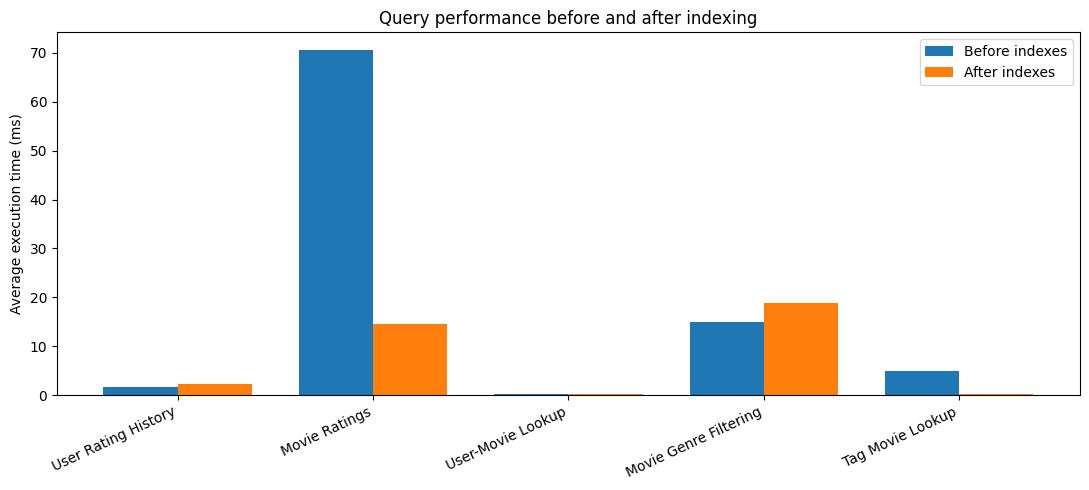

In [15]:

if "before_results" in globals() and "after_results" in globals():
    labels = list(before_results.keys())
    x = np.arange(len(labels))
    width = 0.38
    plt.figure(figsize=(11, 5))
    plt.bar(x - width/2, [before_results[k] for k in labels], width, label="Before indexes")
    plt.bar(x + width/2, [after_results[k] for k in labels], width, label="After indexes")
    plt.xticks(x, labels, rotation=25, ha="right")
    plt.ylabel("Average execution time (ms)")
    plt.title("Query performance before and after indexing")
    plt.legend()
    plt.tight_layout()
    plt.show()
else:
    print("Run the controlled index experiment cell first.")


In [16]:
# 3. Fair Query Performance: Before vs After Indexing

import sqlite3
import time
import statistics

conn = sqlite3.connect(DB_PATH)
cursor = conn.cursor()

# Remove previous benchmark tables
cursor.execute("DROP TABLE IF EXISTS rating_benchmark_no_index")
cursor.execute("DROP TABLE IF EXISTS rating_benchmark_indexed")

# Create two identical empty tables without constraints
cursor.execute("""
CREATE TABLE rating_benchmark_no_index AS
SELECT user_id, movie_id, rating, timestamp
FROM rating
WHERE 0;
""")

cursor.execute("""
CREATE TABLE rating_benchmark_indexed AS
SELECT user_id, movie_id, rating, timestamp
FROM rating
WHERE 0;
""")

# Copy identical data into both tables
cursor.execute("""
INSERT INTO rating_benchmark_no_index
SELECT user_id, movie_id, rating, timestamp FROM rating;
""")

cursor.execute("""
INSERT INTO rating_benchmark_indexed
SELECT user_id, movie_id, rating, timestamp FROM rating;
""")

# Create index only on the indexed table
cursor.execute("""
CREATE INDEX idx_benchmark_user_movie
ON rating_benchmark_indexed(user_id, movie_id);
""")

conn.commit()

# Select an actual rating record
cursor.execute("""
SELECT user_id, movie_id
FROM rating
LIMIT 1;
""")
sample = cursor.fetchone()

if sample is None:
    raise ValueError("No rating records available.")

sample_user, sample_movie = sample

# Query without index
query_without_index = """
SELECT rating
FROM rating_benchmark_no_index
WHERE user_id = ? AND movie_id = ?;
"""

# Query with index
query_with_index = """
SELECT rating
FROM rating_benchmark_indexed
WHERE user_id = ? AND movie_id = ?;
"""

# Display query plans
print("Query plan WITHOUT index:")
cursor.execute(
    "EXPLAIN QUERY PLAN " + query_without_index,
    (sample_user, sample_movie)
)
print(cursor.fetchall())

print("\nQuery plan WITH index:")
cursor.execute(
    "EXPLAIN QUERY PLAN " + query_with_index,
    (sample_user, sample_movie)
)
print(cursor.fetchall())

# Measure execution time
def measure_query(query, repetitions=100):
    timings = []

    for _ in range(repetitions):
        start = time.perf_counter()
        cursor.execute(query, (sample_user, sample_movie))
        cursor.fetchall()
        timings.append(time.perf_counter() - start)

    return statistics.mean(timings)

time_without_index = measure_query(query_without_index)
time_with_index = measure_query(query_with_index)

print("\n--- Performance Comparison ---")
print(f"Without index: {time_without_index:.8f} seconds")
print(f"With index:    {time_with_index:.8f} seconds")

if time_with_index > 0:
    improvement = (
        (time_without_index - time_with_index) / time_without_index
    ) * 100
    print(f"Query time reduction: {improvement:.2f}%")

# Remove benchmark tables
cursor.execute("DROP TABLE rating_benchmark_no_index")
cursor.execute("DROP TABLE rating_benchmark_indexed")

conn.commit()
conn.close()

Query plan WITHOUT index:
[(2, 0, 0, 'SCAN rating_benchmark_no_index')]

Query plan WITH index:
[(3, 0, 0, 'SEARCH rating_benchmark_indexed USING INDEX idx_benchmark_user_movie (user_id=? AND movie_id=?)')]

--- Performance Comparison ---
Without index: 0.06780992 seconds
With index:    0.00031943 seconds
Query time reduction: 99.53%


In [17]:
# 1. Composite Index Column-Order Experiment

import sqlite3
import time
import statistics

conn = sqlite3.connect(DB_PATH)
cursor = conn.cursor()

# Remove old test indexes if they exist
cursor.execute("DROP INDEX IF EXISTS idx_test_user_movie")
cursor.execute("DROP INDEX IF EXISTS idx_test_movie_user")

# Create both composite indexes
cursor.execute("""
CREATE INDEX idx_test_user_movie
ON rating(user_id, movie_id);
""")

cursor.execute("""
CREATE INDEX idx_test_movie_user
ON rating(movie_id, user_id);
""")
conn.commit()

# Select an actual user and movie combination
cursor.execute("""
SELECT user_id, movie_id
FROM rating
LIMIT 1;
""")
sample = cursor.fetchone()

if sample is None:
    raise ValueError("The rating table is empty. Run the ratings ETL first.")

sample_user, sample_movie = sample

queries = [
    (
        "Index order: (user_id, movie_id)",
        """
        SELECT rating
        FROM rating INDEXED BY idx_test_user_movie
        WHERE user_id = ? AND movie_id = ?;
        """
    ),
    (
        "Index order: (movie_id, user_id)",
        """
        SELECT rating
        FROM rating INDEXED BY idx_test_movie_user
        WHERE user_id = ? AND movie_id = ?;
        """
    )
]

for label, query in queries:
    print("\n", label)

    cursor.execute("EXPLAIN QUERY PLAN " + query,
                   (sample_user, sample_movie))
    print("Query plan:", cursor.fetchall())

    times = []

    for _ in range(100):
        start = time.perf_counter()
        cursor.execute(query, (sample_user, sample_movie))
        cursor.fetchall()
        times.append(time.perf_counter() - start)

    print(f"Average execution time: {statistics.mean(times):.8f} seconds")

# Remove experimental indexes after comparison
cursor.execute("DROP INDEX IF EXISTS idx_test_user_movie")
cursor.execute("DROP INDEX IF EXISTS idx_test_movie_user")
conn.commit()
conn.close()


 Index order: (user_id, movie_id)
Query plan: [(3, 0, 0, 'SEARCH rating USING INDEX idx_test_user_movie (user_id=? AND movie_id=?)')]
Average execution time: 0.00024909 seconds

 Index order: (movie_id, user_id)
Query plan: [(3, 0, 0, 'SEARCH rating USING INDEX idx_test_movie_user (movie_id=? AND user_id=?)')]
Average execution time: 0.00030627 seconds


In [18]:
# 2. Index Insertion Overhead Experiment

import sqlite3
import time
import os

conn = sqlite3.connect(DB_PATH)
cursor = conn.cursor()

# Remove old experimental tables
cursor.execute("DROP TABLE IF EXISTS rating_insert_no_index")
cursor.execute("DROP TABLE IF EXISTS rating_insert_with_index")

# Create empty tables with the same columns as rating
cursor.execute("""
CREATE TABLE rating_insert_no_index AS
SELECT user_id, movie_id, rating, timestamp
FROM rating
WHERE 0;
""")

cursor.execute("""
CREATE TABLE rating_insert_with_index AS
SELECT user_id, movie_id, rating, timestamp
FROM rating
WHERE 0;
""")

# Add secondary indexes only to the second table
cursor.execute("""
CREATE INDEX idx_insert_user
ON rating_insert_with_index(user_id);
""")

cursor.execute("""
CREATE INDEX idx_insert_movie
ON rating_insert_with_index(movie_id);
""")

conn.commit()

# Insert data without secondary indexes
start = time.perf_counter()

cursor.execute("""
INSERT INTO rating_insert_no_index
SELECT user_id, movie_id, rating, timestamp
FROM rating;
""")

conn.commit()
no_index_time = time.perf_counter() - start

# Insert the same data with secondary indexes
start = time.perf_counter()

cursor.execute("""
INSERT INTO rating_insert_with_index
SELECT user_id, movie_id, rating, timestamp
FROM rating;
""")

conn.commit()
with_index_time = time.perf_counter() - start

# Display results
cursor.execute("SELECT COUNT(*) FROM rating_insert_no_index")
row_count = cursor.fetchone()[0]

print("Rows inserted:", f"{row_count:,}")
print(f"Insertion time without secondary indexes: {no_index_time:.4f} seconds")
print(f"Insertion time with secondary indexes:    {with_index_time:.4f} seconds")

if no_index_time > 0:
    overhead = ((with_index_time - no_index_time) / no_index_time) * 100
    print(f"Index insertion overhead: {overhead:.2f}%")

# Clean up experimental tables
cursor.execute("DROP TABLE rating_insert_no_index")
cursor.execute("DROP TABLE rating_insert_with_index")

conn.commit()
conn.close()

Rows inserted: 991,618
Insertion time without secondary indexes: 2.6154 seconds
Insertion time with secondary indexes:    359.8976 seconds
Index insertion overhead: 13660.57%


## 13. EXPLAIN QUERY PLAN

In [19]:
# STEP 5: EXPLAIN QUERY PLAN — INDEX UTILIZATION

import sqlite3

db_path = DB_PATH

conn = sqlite3.connect(db_path)
cursor = conn.cursor()

queries = {
    "User Rating History": """
        SELECT * FROM rating
        WHERE user_id = 320;
    """,

    "Movie Ratings": """
        SELECT * FROM rating
        WHERE movie_id = 1;
    """,

    "User-Movie Lookup": """
        SELECT * FROM rating
        WHERE user_id = 320 AND movie_id = 1;
    """,

    "Movie Genre Filtering": """
        SELECT movie_id FROM movie_genre
        WHERE genre_id = 1;
    """,

    "Tag Movie Lookup": """
        SELECT * FROM tag_event
        WHERE movie_id = 1;
    """
}

print("=== SQLITE QUERY EXECUTION PLANS ===")

for query_name, sql in queries.items():

    print(f"\n--- {query_name} ---")

    cursor.execute("EXPLAIN QUERY PLAN " + sql)

    for row in cursor.fetchall():
        print(row)

conn.close()

print("\nQuery plan analysis completed.")


=== SQLITE QUERY EXECUTION PLANS ===

--- User Rating History ---
(3, 0, 0, 'SEARCH rating USING INDEX idx_rating_user_movie (user_id=?)')

--- Movie Ratings ---
(3, 0, 0, 'SEARCH rating USING INDEX idx_rating_movie_id (movie_id=?)')

--- User-Movie Lookup ---
(3, 0, 0, 'SEARCH rating USING INDEX sqlite_autoindex_rating_1 (user_id=? AND movie_id=?)')

--- Movie Genre Filtering ---
(3, 0, 0, 'SEARCH movie_genre USING INDEX idx_movie_genre_genre (genre_id=?)')

--- Tag Movie Lookup ---
(3, 0, 0, 'SEARCH tag_event USING INDEX idx_tag_event_movie_id (movie_id=?)')

Query plan analysis completed.


## 14. MOVIE_STATS precomputed aggregation

In [20]:
# STEP 6: MOVIE_STATS — PRECOMPUTED AGGREGATION

import sqlite3
import time

db_path = DB_PATH

conn = sqlite3.connect(db_path)
cursor = conn.cursor()

cursor.execute("PRAGMA foreign_keys = ON;")

print("=== CREATING MOVIE_STATS TABLE ===")

cursor.execute("""
CREATE TABLE IF NOT EXISTS movie_stats (
    movie_id INTEGER PRIMARY KEY,
    rating_count INTEGER NOT NULL DEFAULT 0,
    average_rating REAL NOT NULL DEFAULT 0,
    FOREIGN KEY (movie_id)
        REFERENCES movie(movie_id)
        ON DELETE CASCADE
);
""")

conn.commit()

print("MOVIE_STATS table created or already exists.")

# Clear old statistics before rebuilding
cursor.execute("DELETE FROM movie_stats;")
conn.commit()

print("\n=== CALCULATING MOVIE STATISTICS ===")

start_time = time.perf_counter()

cursor.execute("""
INSERT INTO movie_stats (movie_id, rating_count, average_rating)
SELECT
    m.movie_id,
    COUNT(r.rating_id),
    COALESCE(AVG(r.rating), 0)
FROM movie m
LEFT JOIN rating r
    ON m.movie_id = r.movie_id
GROUP BY m.movie_id;
""")

conn.commit()

calculation_time = time.perf_counter() - start_time

print(f"Statistics calculation time: {calculation_time:.4f} seconds")

# Verify results
cursor.execute("SELECT COUNT(*) FROM movie_stats;")
print("Total movie statistics records:", cursor.fetchone()[0])

print("\n=== TOP 10 MOVIES BY RATING COUNT ===")

cursor.execute("""
SELECT m.title, ms.rating_count, ROUND(ms.average_rating, 2)
FROM movie_stats ms
JOIN movie m ON ms.movie_id = m.movie_id
ORDER BY ms.rating_count DESC
LIMIT 10;
""")

for row in cursor.fetchall():
    print(row)

conn.close()

print("\nMOVIE_STATS population completed.")


=== CREATING MOVIE_STATS TABLE ===
MOVIE_STATS table created or already exists.

=== CALCULATING MOVIE STATISTICS ===
Statistics calculation time: 2.8301 seconds
Total movie statistics records: 87585

=== TOP 10 MOVIES BY RATING COUNT ===
('Shawshank Redemption, The', 3201, 4.38)
('Forrest Gump', 3140, 4.06)
('Pulp Fiction', 3031, 4.21)
('Matrix, The', 2917, 4.13)
('Silence of the Lambs, The', 2796, 4.17)
('Star Wars: Episode IV - A New Hope', 2658, 4.12)
('Fight Club', 2370, 4.25)
('Jurassic Park', 2333, 3.71)
("Schindler's List", 2308, 4.26)
('Lord of the Rings: The Fellowship of the Ring, The', 2273, 4.09)

MOVIE_STATS population completed.


## 15. Live versus precomputed aggregation

In [21]:
# STEP 7: LIVE VS PRECOMPUTED AGGREGATION PERFORMANCE

import sqlite3
import time
import statistics

db_path = DB_PATH

conn = sqlite3.connect(db_path)
cursor = conn.cursor()

live_query = """
SELECT
    movie_id,
    COUNT(rating_id),
    AVG(rating)
FROM rating
GROUP BY movie_id;
"""

precomputed_query = """
SELECT
    movie_id,
    rating_count,
    average_rating
FROM movie_stats;
"""

def measure_query(query, runs=10):
    execution_times = []

    # Warm-up
    cursor.execute(query)
    cursor.fetchall()

    for _ in range(runs):
        start = time.perf_counter()

        cursor.execute(query)
        results = cursor.fetchall()

        end = time.perf_counter()

        execution_times.append((end - start) * 1000)

    return (
        statistics.mean(execution_times),
        statistics.stdev(execution_times),
        len(results)
    )

print("=== LIVE AGGREGATION ===")

live_avg, live_std, live_count = measure_query(live_query)

print(f"Average time: {live_avg:.4f} ms")
print(f"Standard deviation: {live_std:.4f} ms")
print(f"Records returned: {live_count:,}")

print("\n=== PRECOMPUTED AGGREGATION ===")

pre_avg, pre_std, pre_count = measure_query(precomputed_query)

print(f"Average time: {pre_avg:.4f} ms")
print(f"Standard deviation: {pre_std:.4f} ms")
print(f"Records returned: {pre_count:,}")

print("\n=== PERFORMANCE COMPARISON ===")

if pre_avg > 0:
    speedup = live_avg / pre_avg
    improvement = ((live_avg - pre_avg) / live_avg) * 100

    print(f"Live aggregation: {live_avg:.4f} ms")
    print(f"Precomputed: {pre_avg:.4f} ms")
    print(f"Speedup: {speedup:.2f}x")
    print(f"Time reduction: {improvement:.2f}%")

print("\nPrecomputed aggregation experiment completed.")

conn.close()

# STEP 7B: FAIR LIVE VS PRECOMPUTED COMPARISON

import sqlite3
import time
import statistics

db_path = DB_PATH

conn = sqlite3.connect(db_path)
cursor = conn.cursor()

live_query = """
SELECT
    m.movie_id,
    COUNT(r.rating_id) AS rating_count,
    COALESCE(AVG(r.rating), 0) AS average_rating
FROM movie m
LEFT JOIN rating r ON m.movie_id = r.movie_id
GROUP BY m.movie_id;
"""

precomputed_query = """
SELECT movie_id, rating_count, average_rating
FROM movie_stats;
"""

def benchmark(query, runs=10):
    times = []
    results = None

    cursor.execute(query)
    results = cursor.fetchall()  # Warm-up

    for _ in range(runs):
        start = time.perf_counter()
        cursor.execute(query)
        results = cursor.fetchall()
        end = time.perf_counter()

        times.append((end - start) * 1000)

    return statistics.mean(times), statistics.stdev(times), results

live_time, live_std, live_data = benchmark(live_query)
pre_time, pre_std, pre_data = benchmark(precomputed_query)

print("=== EQUIVALENT RESULT VERIFICATION ===")
print("Live records:", len(live_data))
print("Precomputed records:", len(pre_data))

# Compare values by movie ID
live_map = {row[0]: (row[1], row[2]) for row in live_data}
pre_map = {row[0]: (row[1], row[2]) for row in pre_data}

mismatches = []

for movie_id in live_map:
    live_count, live_avg = live_map[movie_id]
    pre_count, pre_avg = pre_map.get(movie_id, (None, None))

    if pre_count != live_count or abs(live_avg - pre_avg) > 1e-9:
        mismatches.append(movie_id)

print("Mismatched movie records:", len(mismatches))

print("\n=== FAIR PERFORMANCE COMPARISON ===")
print(f"Live aggregation: {live_time:.4f} ms (SD: {live_std:.4f})")
print(f"Precomputed:      {pre_time:.4f} ms (SD: {pre_std:.4f})")

if pre_time > 0:
    print(f"Speedup: {live_time / pre_time:.2f}x")
    print(f"Time reduction: {(live_time - pre_time) / live_time * 100:.2f}%")

conn.close()


=== LIVE AGGREGATION ===
Average time: 2209.9208 ms
Standard deviation: 448.7301 ms
Records returned: 27,752

=== PRECOMPUTED AGGREGATION ===
Average time: 175.0143 ms
Standard deviation: 7.1555 ms
Records returned: 87,585

=== PERFORMANCE COMPARISON ===
Live aggregation: 2209.9208 ms
Precomputed: 175.0143 ms
Speedup: 12.63x
Time reduction: 92.08%

Precomputed aggregation experiment completed.
=== EQUIVALENT RESULT VERIFICATION ===
Live records: 87585
Precomputed records: 87585
Mismatched movie records: 0

=== FAIR PERFORMANCE COMPARISON ===
Live aggregation: 2795.8232 ms (SD: 562.7347)
Precomputed:      121.0030 ms (SD: 31.6146)
Speedup: 23.11x
Time reduction: 95.67%


### 15.1 Visual comparison of live and precomputed aggregation
This chart visualizes the measured average execution times for the equivalent aggregate queries.

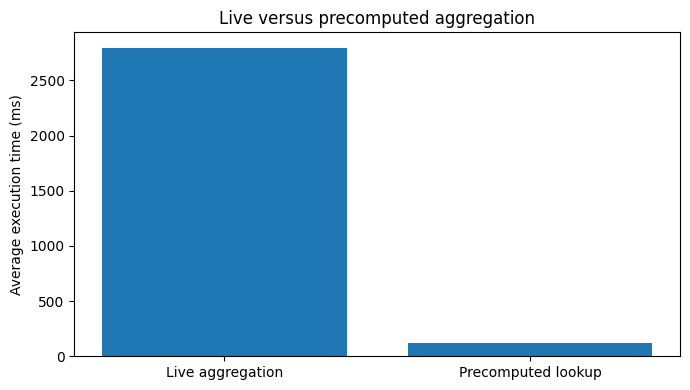

In [22]:

if "live_time" in globals() and "pre_time" in globals():
    plt.figure(figsize=(7, 4))
    plt.bar(["Live aggregation", "Precomputed lookup"], [live_time, pre_time])
    plt.ylabel("Average execution time (ms)")
    plt.title("Live versus precomputed aggregation")
    plt.tight_layout()
    plt.show()
else:
    print("Run the fair aggregation benchmark cell first.")


## 16. ACID properties and transaction demonstrations

In [23]:
# STEP 8: ACID PROPERTIES — TRANSACTION AND ROLLBACK

import sqlite3

db_path = DB_PATH

conn = sqlite3.connect(db_path)
cursor = conn.cursor()

cursor.execute("PRAGMA foreign_keys = ON;")

test_user_id = -888888

print("=== ACID TRANSACTION DEMONSTRATION ===")

try:
    # Begin transaction
    cursor.execute("BEGIN TRANSACTION;")

    # Insert temporary user
    cursor.execute(
        "INSERT INTO app_user (user_id) VALUES (?);",
        (test_user_id,)
    )

    # Verify inside transaction
    cursor.execute(
        "SELECT COUNT(*) FROM app_user WHERE user_id = ?;",
        (test_user_id,)
    )

    inside_count = cursor.fetchone()[0]

    print("User exists inside transaction:", inside_count == 1)

    # Roll back transaction
    conn.rollback()

    # Verify after rollback
    cursor.execute(
        "SELECT COUNT(*) FROM app_user WHERE user_id = ?;",
        (test_user_id,)
    )

    after_count = cursor.fetchone()[0]

    print("User exists after rollback:", after_count == 1)

    if inside_count == 1 and after_count == 0:
        print("\nRollback successful. Transaction changes were undone.")
    else:
        print("\nTransaction verification failed.")

except Exception:
    conn.rollback()
    raise

finally:
    conn.close()

print("\nACID rollback demonstration completed.")

# STEP 8B: ACID PROPERTIES — CONSISTENCY, ISOLATION AND DURABILITY

import sqlite3

db_path = DB_PATH

test_user_id = -888887

print("=== 1. CONSISTENCY TEST ===")

conn = sqlite3.connect(db_path)
cursor = conn.cursor()
cursor.execute("PRAGMA foreign_keys = ON;")

try:
    cursor.execute("""
        INSERT INTO rating (user_id, movie_id, rating, timestamp)
        VALUES (?, 1, 5.0, 100000);
    """, (test_user_id,))

    conn.commit()
    print("Consistency test failed: Invalid rating accepted.")

except sqlite3.IntegrityError:
    conn.rollback()
    print("Consistency test passed: Invalid foreign key rejected.")

conn.close()


print("\n=== 2. ISOLATION TEST ===")

conn1 = sqlite3.connect(db_path)
conn2 = sqlite3.connect(db_path)

try:
    conn1.execute("BEGIN TRANSACTION;")

    conn1.execute(
        "INSERT INTO app_user (user_id) VALUES (?);",
        (test_user_id,)
    )

    cursor2 = conn2.cursor()
    cursor2.execute(
        "SELECT COUNT(*) FROM app_user WHERE user_id = ?;",
        (test_user_id,)
    )

    visible_count = cursor2.fetchone()[0]

    print("Uncommitted user visible to second connection:",
          visible_count == 1)

    conn1.rollback()

    print("Isolation test passed:",
          visible_count == 0)

finally:
    conn1.close()
    conn2.close()


print("\n=== 3. DURABILITY TEST ===")

# Commit data and close connection
conn = sqlite3.connect(db_path)
cursor = conn.cursor()

cursor.execute(
    "INSERT OR IGNORE INTO app_user (user_id) VALUES (?);",
    (test_user_id,)
)

conn.commit()
conn.close()

# Reopen database and verify committed data
conn = sqlite3.connect(db_path)
cursor = conn.cursor()

cursor.execute(
    "SELECT COUNT(*) FROM app_user WHERE user_id = ?;",
    (test_user_id,)
)

persisted_count = cursor.fetchone()[0]

print("Committed data exists after reopening:",
      persisted_count == 1)

# Clean up temporary test user
cursor.execute(
    "DELETE FROM app_user WHERE user_id = ?;",
    (test_user_id,)
)

conn.commit()
conn.close()

print("\nACID property demonstration completed.")


=== ACID TRANSACTION DEMONSTRATION ===
User exists inside transaction: True
User exists after rollback: False

Rollback successful. Transaction changes were undone.

ACID rollback demonstration completed.
=== 1. CONSISTENCY TEST ===
Consistency test passed: Invalid foreign key rejected.

=== 2. ISOLATION TEST ===
Uncommitted user visible to second connection: False
Isolation test passed: True

=== 3. DURABILITY TEST ===
Committed data exists after reopening: True

ACID property demonstration completed.


## 17. CSV sampling/scalability experiment

In [24]:
# STEP 9: DATABASE SCALABILITY EXPERIMENT

import pandas as pd
import time
import statistics

ratings_path = os.path.join(DATA_DIR, 'ratings.csv')

mod_values = [32, 16, 8, 4]
chunksize = 200_000
runs = 5

# Count ratings for each deterministic sample
sample_counts = {mod: 0 for mod in mod_values}

print("=== CALCULATING SAMPLE SIZES ===")

for chunk in pd.read_csv(ratings_path, chunksize=chunksize):

    for mod in mod_values:
        sample_counts[mod] += (
            chunk['userId'] % mod == 0
        ).sum()

for mod in mod_values:
    print(
        f"Stage {mod}: UserId % {mod} == 0 | "
        f"Ratings: {sample_counts[mod]:,}"
    )


# Benchmark processing time for each sample
print("\n=== SCALABILITY PROCESSING BENCHMARK ===")

performance_results = {}

for mod in mod_values:

    execution_times = []

    for _ in range(runs):

        start = time.perf_counter()
        rows_processed = 0

        for chunk in pd.read_csv(
            ratings_path,
            usecols=['userId', 'movieId', 'rating'],
            chunksize=chunksize
        ):

            subset = chunk[chunk['userId'] % mod == 0]
            rows_processed += len(subset)

        end = time.perf_counter()

        execution_times.append((end - start) * 1000)

    avg_time = statistics.mean(execution_times)
    std_time = statistics.stdev(execution_times)

    performance_results[mod] = (rows_processed, avg_time, std_time)

    print(f"\nStage {mod} (mod {mod})")
    print(f"Ratings processed: {rows_processed:,}")
    print(f"Average time: {avg_time:.2f} ms")
    print(f"Standard deviation: {std_time:.2f} ms")


print("\n=== FINAL SCALABILITY SUMMARY ===")

for mod in mod_values:
    count, avg, std = performance_results[mod]

    print(
        f"Mod {mod:<3} | Ratings: {count:>10,} | "
        f"Average: {avg:>10.2f} ms | SD: {std:.2f} ms"
    )

print("\nScalability experiment completed.")


=== CALCULATING SAMPLE SIZES ===
Stage 32: UserId % 32 == 0 | Ratings: 991,618
Stage 16: UserId % 16 == 0 | Ratings: 1,954,519
Stage 8: UserId % 8 == 0 | Ratings: 3,878,599
Stage 4: UserId % 4 == 0 | Ratings: 7,862,045

=== SCALABILITY PROCESSING BENCHMARK ===

Stage 32 (mod 32)
Ratings processed: 991,618
Average time: 16936.74 ms
Standard deviation: 710.25 ms

Stage 16 (mod 16)
Ratings processed: 1,954,519
Average time: 15416.82 ms
Standard deviation: 110.60 ms

Stage 8 (mod 8)
Ratings processed: 3,878,599
Average time: 15223.10 ms
Standard deviation: 74.74 ms

Stage 4 (mod 4)
Ratings processed: 7,862,045
Average time: 15235.18 ms
Standard deviation: 164.08 ms

=== FINAL SCALABILITY SUMMARY ===
Mod 32  | Ratings:    991,618 | Average:   16936.74 ms | SD: 710.25 ms
Mod 16  | Ratings:  1,954,519 | Average:   15416.82 ms | SD: 110.60 ms
Mod 8   | Ratings:  3,878,599 | Average:   15223.10 ms | SD: 74.74 ms
Mod 4   | Ratings:  7,862,045 | Average:   15235.18 ms | SD: 164.08 ms

Scalability


## 17.1 Index storage overhead

Indexes improve selected read queries but consume storage and add work to insert, update and delete operations. This section measures explicit index storage using SQLite's `dbstat` virtual table when supported. The fallback reports whole-database page usage and clearly notes that it cannot isolate individual index sizes.


In [25]:

storage_conn = sqlite3.connect(DB_PATH)
page_size = storage_conn.execute("PRAGMA page_size").fetchone()[0]
print("SQLite page size:", page_size, "bytes")

try:
    dbstat_rows = storage_conn.execute(
        "SELECT name, SUM(pgsize) FROM dbstat GROUP BY name ORDER BY SUM(pgsize) DESC"
    ).fetchall()
    index_rows = [(name, size) for name, size in dbstat_rows
                  if name.startswith("idx_") or name.startswith("sqlite_autoindex")]
    for name, size in index_rows:
        print(f"{name}: {size:,} bytes ({size / 1024 / 1024:.2f} MB)")
    print("Total reported index storage:",
          f"{sum(size for _, size in index_rows):,} bytes")
except sqlite3.OperationalError as error:
    print("SQLite dbstat is unavailable:", error)
    page_count = storage_conn.execute("PRAGMA page_count").fetchone()[0]
    free_pages = storage_conn.execute("PRAGMA freelist_count").fetchone()[0]
    print("Whole database allocated size:",
          f"{page_count * page_size:,} bytes")
    print("Free-list size:", f"{free_pages * page_size:,} bytes")
    print("This fallback does not isolate index storage.")

print("SQLite database file size:",
      f"{os.path.getsize(DB_PATH):,} bytes")
storage_conn.close()


SQLite page size: 4096 bytes
sqlite_autoindex_rating_1: 17,059,840 bytes (16.27 MB)
idx_rating_user_movie: 14,979,072 bytes (14.29 MB)
idx_rating_user_id: 11,759,616 bytes (11.21 MB)
idx_rating_movie_id: 11,165,696 bytes (10.65 MB)
sqlite_autoindex_movie_genre_1: 2,289,664 bytes (2.18 MB)
idx_movie_genre_genre: 1,445,888 bytes (1.38 MB)
idx_tag_event_movie_id: 475,136 bytes (0.45 MB)
sqlite_autoindex_genre_1: 4,096 bytes (0.00 MB)
Total reported index storage: 59,179,008 bytes
SQLite database file size: 163,368,960 bytes



## 17.2 SQLite database scalability experiment

The original CSV scalability experiment measures how long it takes to scan/filter progressively larger deterministic samples of the source CSV. This additional experiment measures SQL query performance on progressively larger SQLite tables. It uses a **separate benchmark database** and does not modify the main CineSearch database.

The experiment loads the same user-based stages (`% 32`, `% 16`, `% 8`, `% 4`) into a temporary benchmark table and times a fixed set of movie-lookup aggregate queries without an explicit index. It then adds an index and compares the final stage. Timings will vary by Colab runtime and storage.


Stage 32: 991,618 rows loaded; mean query workload 601.721 ms
Stage 16: 1,954,519 rows loaded; mean query workload 1421.934 ms
Stage 8: 3,878,599 rows loaded; mean query workload 3451.757 ms
Stage 4: 7,862,045 rows loaded; mean query workload 7195.756 ms


,sampling_rule,rating_rows,load_time_seconds,unindexed_query_mean_ms,unindexed_query_sd_ms
0,userId % 32 == 0,991618,20.33,601.720763,13.677247
1,userId % 16 == 0,1954519,25.32,1421.934437,380.424485
2,userId % 8 == 0,3878599,30.70,3451.756882,1111.521674
3,userId % 4 == 0,7862045,45.07,7195.756298,2068.833204


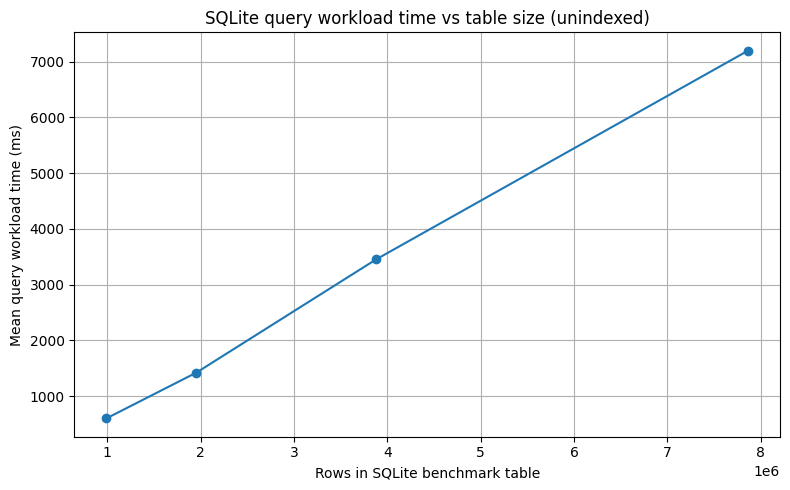

Largest stage — unindexed: 7195.756 ms
Largest stage — indexed:   560.084 ms
Observed speedup: 12.85x


In [26]:

SCALABILITY_DB = os.path.join(DATABASE_DIR, "cinesearch_scalability.db")
SCALABILITY_STAGES = [32, 16, 8, 4]
SCALABILITY_CHUNK_SIZE = 200_000
SCALABILITY_REPEATS = 5

if os.path.exists(SCALABILITY_DB):
    os.remove(SCALABILITY_DB)

scale_conn = sqlite3.connect(SCALABILITY_DB)
scale_conn.execute("""
CREATE TABLE rating_bench (
    user_id INTEGER NOT NULL,
    movie_id INTEGER NOT NULL,
    rating REAL NOT NULL,
    timestamp INTEGER NOT NULL
)
""")
scale_conn.commit()

movie_lookup_ids = [1, 2, 3, 10, 32, 50, 100, 296, 500, 1000]
lookup_sql = "SELECT COUNT(*), AVG(rating) FROM rating_bench WHERE movie_id = ?"
scale_results = []

for divisor in SCALABILITY_STAGES:
    scale_conn.execute("DELETE FROM rating_bench")
    scale_conn.commit()
    row_count = 0
    load_start = time.perf_counter()

    for data_chunk in pd.read_csv(os.path.join(DATA_DIR, "ratings.csv"),
                                  chunksize=SCALABILITY_CHUNK_SIZE):
        sample_chunk = data_chunk[data_chunk["userId"] % divisor == 0]
        if sample_chunk.empty:
            continue
        records = list(sample_chunk[
            ["userId", "movieId", "rating", "timestamp"]
        ].itertuples(index=False, name=None))
        scale_conn.executemany(
            "INSERT INTO rating_bench VALUES (?, ?, ?, ?)", records
        )
        row_count += len(records)

    scale_conn.commit()
    load_seconds = time.perf_counter() - load_start

    query_times = []
    for _ in range(SCALABILITY_REPEATS):
        start = time.perf_counter()
        for movie_id in movie_lookup_ids:
            scale_conn.execute(lookup_sql, (movie_id,)).fetchone()
        query_times.append((time.perf_counter() - start) * 1000)

    scale_results.append({
        "sampling_rule": f"userId % {divisor} == 0",
        "rating_rows": row_count,
        "load_time_seconds": round(load_seconds, 2),
        "unindexed_query_mean_ms": float(np.mean(query_times)),
        "unindexed_query_sd_ms": float(np.std(query_times, ddof=1))
    })
    print(f"Stage {divisor}: {row_count:,} rows loaded; "
          f"mean query workload {np.mean(query_times):.3f} ms")

scale_df = pd.DataFrame(scale_results)
display(scale_df)

plt.figure(figsize=(8, 5))
plt.plot(scale_df["rating_rows"], scale_df["unindexed_query_mean_ms"], marker="o")
plt.xlabel("Rows in SQLite benchmark table")
plt.ylabel("Mean query workload time (ms)")
plt.title("SQLite query workload time vs table size (unindexed)")
plt.grid(True)
plt.tight_layout()
plt.show()

largest_unindexed_ms = float(scale_df.iloc[-1]["unindexed_query_mean_ms"])
scale_conn.execute("CREATE INDEX idx_rating_bench_movie ON rating_bench(movie_id)")
scale_conn.commit()

indexed_times = []
for _ in range(SCALABILITY_REPEATS):
    start = time.perf_counter()
    for movie_id in movie_lookup_ids:
        scale_conn.execute(lookup_sql, (movie_id,)).fetchone()
    indexed_times.append((time.perf_counter() - start) * 1000)

largest_indexed_ms = float(np.mean(indexed_times))
print(f"Largest stage — unindexed: {largest_unindexed_ms:.3f} ms")
print(f"Largest stage — indexed:   {largest_indexed_ms:.3f} ms")
if largest_indexed_ms > 0:
    print(f"Observed speedup: {largest_unindexed_ms / largest_indexed_ms:.2f}x")

scale_conn.close()


## 18. Final database verification

In [27]:
# STEP 10: FINAL DATABASE VERIFICATION

import sqlite3
import os

db_path = DB_PATH

conn = sqlite3.connect(db_path)
cursor = conn.cursor()
cursor.execute("PRAGMA foreign_keys = ON;")

print("=== FINAL DATABASE TABLE VERIFICATION ===")

tables = [
    'movie',
    'genre',
    'movie_genre',
    'app_user',
    'rating',
    'tag_event',
    'movie_stats'
]

for table in tables:
    cursor.execute(f"SELECT COUNT(*) FROM {table};")
    count = cursor.fetchone()[0]
    print(f"{table:<15} | {count:>12,} rows")

print("\n=== INDEX VERIFICATION ===")

cursor.execute("""
SELECT name, tbl_name
FROM sqlite_master
WHERE type = 'index'
ORDER BY tbl_name, name;
""")

for index in cursor.fetchall():
    print(f"{index[0]:<35} | Table: {index[1]}")

print("\n=== FOREIGN KEY VERIFICATION ===")

cursor.execute("PRAGMA foreign_key_check;")
violations = cursor.fetchall()

print("Foreign key violations:", len(violations))

print("\n=== DATABASE SIZE ===")

db_size = os.path.getsize(db_path) / (1024 * 1024)
print(f"Database size: {db_size:.2f} MB")

print("\n=== FINAL VERIFICATION COMPLETED ===")

conn.close()


=== FINAL DATABASE TABLE VERIFICATION ===
movie           |       87,585 rows
genre           |           19 rows
movie_genre     |      147,090 rows
app_user        |        6,279 rows
rating          |      991,618 rows
tag_event       |       40,575 rows
movie_stats     |       87,585 rows

=== INDEX VERIFICATION ===
sqlite_autoindex_genre_1            | Table: genre
idx_movie_genre_genre               | Table: movie_genre
sqlite_autoindex_movie_genre_1      | Table: movie_genre
idx_rating_movie_id                 | Table: rating
idx_rating_user_id                  | Table: rating
idx_rating_user_movie               | Table: rating
sqlite_autoindex_rating_1           | Table: rating
idx_tag_event_movie_id              | Table: tag_event

=== FOREIGN KEY VERIFICATION ===
Foreign key violations: 0

=== DATABASE SIZE ===
Database size: 155.80 MB

=== FINAL VERIFICATION COMPLETED ===
